# Lab 7 — Planning and Learning: Trajectory Sampling and MCTS

**Course:** Reinforcement Learning
**Student:** Amartya Ranjan — Registration Number 23BRS1309
**Date of Submission:** 17 September 2026
**Reference text:** Sutton & Barto, *Reinforcement Learning: An Introduction* (2nd ed.), Chapter 8 — *Planning and Learning*
**Programs analyzed:** `trajectory_sampling.py` (Figure 8.8 experiment) and `MCTS.py` (UCT on a 3×3 grid world)

---

This notebook answers the eight laboratory questions on **trajectory sampling** with an
experiment-driven walkthrough, then analyses the **Monte Carlo Tree Search (MCTS)** program.
Every experiment below is executed top-to-bottom with a fixed seed (`SEED = 2026`); all figures
shown are produced by this very run and are embedded in the submitted PDF report
(`Lab7_Report_AmartyaRanjan_23BRS1309.pdf`).


## 0 · Programs under analysis

**`trajectory_sampling.py`** implements the Figure 8.8 experiment of Section 8.5. A *task* is a
randomly generated MDP with `n_states` non-terminal states, two actions, and a branching factor
`b`: each state–action pair leads to `b` possible next states, each with its own $\mathcal{N}(0,1)$
reward. Every step terminates the episode with probability `TERMINATION_PROB = 0.1` (equivalently,
$\gamma = 1 - p = 0.9$). Two **expected (full) update** planners are compared:

* `uniform` — sweeps the state–action pairs in a deterministic cyclic order;
* `on_policy` — follows simulated trajectories generated by an $arepsilon$-greedy behaviour
  policy ($arepsilon = 0.1$), updating only the pairs actually traversed.

Performance is the Monte-Carlo estimate of the value of the start state under the greedy policy
derived from $q$, evaluated by `evaluate_pi` every `eval_interval` updates.

**`MCTS.py`** implements Monte Carlo Tree Search with UCT (exploration constant $C=\sqrt{2}$) on a
3×3 grid world: start `S` at (0,0), goal `T` at (2,2) paying +10 on arrival, a dangerous cell
`D` at (1,1) paying −5, every other arrival −1, invalid moves self-loop. Each simulation runs the
four phases (selection → expansion → rollout → backpropagation); the final action is the most
visited child of the root.


In [1]:
# Global setup — reference logic of trajectory_sampling.py, parameterised for the lab questions
import numpy as np
import matplotlib.pyplot as plt
import os, math, time

SEED = 2026
os.makedirs('figures', exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'font.size': 10.5, 'axes.titlesize': 11.5, 'legend.frameon': False,
    'axes.unicode_minus': False,
})
C_ON, C_UN = '#3681a6', '#b43a4e'          # on-policy (blue) vs uniform (red)
B_STYLE = {1: '-', 3: '--', 10: ':'}        # linestyle per branching factor

ACTIONS = [0, 1]

def argmax(value):
    '''Greedy action with ties broken uniformly at random (as in the reference program).'''
    max_q = np.max(value)
    return np.random.choice([a for a, q in enumerate(value) if q == max_q])

class Task:
    '''Random MDP: n_states non-terminal states, |A|=2, branching factor b.'''
    def __init__(self, n_states, b):
        self.n_states = n_states
        self.b = b
        self.transition = np.random.randint(n_states, size=(n_states, len(ACTIONS), b))
        self.reward = np.random.randn(n_states, len(ACTIONS), b)

    def step(self, state, action):
        if np.random.rand() < TERMINATION_PROB:
            return self.n_states, 0
        next_ = np.random.randint(self.b)
        return self.transition[state, action, next_], self.reward[state, action, next_]

TERMINATION_PROB = 0.1     # p: per-step probability of episode termination  (gamma = 1 - p)
EPSILON = 0.1              # behaviour-policy exploration rate for on_policy

def evaluate_pi(q, task, runs=100):
    '''Monte-Carlo estimate of the start-state value of the greedy policy w.r.t. q.'''
    returns = []
    for _ in range(runs):
        rewards, state = 0, 0
        while state < task.n_states:
            action = argmax(q[state])
            state, r = task.step(state, action)
            rewards += r
        returns.append(rewards)
    return np.mean(returns)

def uniform_run(task, max_steps, eval_interval, eval_runs=100):
    '''Expected updates from a uniform distribution over state-action pairs (cyclic sweep).'''
    perf, q = [], np.zeros((task.n_states, 2))
    for step in range(max_steps):
        state = step // len(ACTIONS) % task.n_states
        action = step % len(ACTIONS)
        next_states = task.transition[state, action]
        q[state, action] = (1 - TERMINATION_PROB) * np.mean(
            task.reward[state, action] + np.max(q[next_states, :], axis=1))
        if step % eval_interval == 0:
            perf.append([step, evaluate_pi(q, task, eval_runs)])
    return q, zip(*perf)

def on_policy_run(task, max_steps, eval_interval, eval_runs=100, eps=EPSILON):
    '''Expected updates along simulated epsilon-greedy trajectories (on-policy distribution).'''
    perf, q = [], np.zeros((task.n_states, 2))
    state = 0
    for step in range(max_steps):
        action = np.random.choice(ACTIONS) if np.random.rand() < eps else argmax(q[state])
        next_state, _ = task.step(state, action)
        next_states = task.transition[state, action]
        q[state, action] = (1 - TERMINATION_PROB) * np.mean(
            task.reward[state, action] + np.max(q[next_states, :], axis=1))
        state = 0 if next_state == task.n_states else next_state
        if step % eval_interval == 0:
            perf.append([step, evaluate_pi(q, task, eval_runs)])
    return q, zip(*perf)

def grid_experiment(n_states_list, b_list, max_steps, eval_interval, n_tasks, eval_runs, seed):
    '''Run both methods over a grid of (n_states, b); average value curves over tasks.'''
    out = {}
    for n in n_states_list:
        for b in b_list:
            for method_name, method in [('on_policy', on_policy_run), ('uniform', uniform_run)]:
                curves = []
                for t in range(n_tasks):
                    np.random.seed(seed + 1000 * t + 17 * b + n)
                    _, (steps, vals) = method(Task(n, b), max_steps, eval_interval, eval_runs)
                    curves.append(list(vals))
                out[(n, b, method_name)] = (list(steps), np.mean(np.asarray(curves), axis=0))
    return out

print('Setup complete — SEED =', SEED)


Setup complete — SEED = 2026


## Part A · Trajectory sampling (Sutton & Barto, Section 8.5)

### Question 1 — How is the state–action pair selected in `uniform` and `on_policy`?

> *Analyze how the state–action pair is selected in the following two methods:
> `uniform(task, eval_interval)` and `on_policy(task, eval_interval)`.*

**`uniform` — a deterministic cyclic sweep over the explicit model.** The update index alone
determines the pair:
`state = step // len(ACTIONS) % n_states`, `action = step % len(ACTIONS)`.
Because `len(ACTIONS) = 2`, pairs are visited in the order (s₀,a₀), (s₀,a₁), (s₁,a₀), (s₁,a₁), …
so the method performs **one complete sweep of all 2·n_states pairs every 2·n_states updates**,
in exactly the same order on every sweep, independent of anything the agent has learned. The
sampling distribution is the *uniform distribution over state–action pairs* $\tfrac{1}{|S||A|}$ —
this is the "expected update" analog of exhaustive dynamic programming, and it uses only the
explicit model arrays (`task.transition`, `task.reward`), never simulated experience.

**`on_policy` — sampling along simulated experience.** Here the pair is whatever the agent is
currently *experiencing*. A persistent state variable starts at 0; at each step the action comes
from an **ε-greedy behaviour policy** w.r.t. the current $q$ (with probability ε a random action,
otherwise `argmax(q[state])` with random tie-breaking), the environment (or model) generates the
stochastic transition through `task.step`, the update is applied to the traversed pair
`(state, action)`, and the state variable moves to `next_state` — restarting from 0 whenever an
episode terminates. The induced sampling distribution is the **on-policy distribution**
$\mu(s,a)\approx\pi_{\text{behaviour}}(a|s)\,d_\pi(s)$: pairs are visited in proportion to how
often the *behaviour* actually encounters them, so sampling effort automatically concentrates on
the region of the state space reachable from the start state under the current policy.


In [2]:
# Q1 demonstration: first 12 selected pairs under each distribution (1000-state task, b=3)
np.random.seed(SEED)
task_demo = Task(1000, 3)

# uniform: purely index-driven, independent of q
uni_pairs = [(step // 2 % 1000, step % 2) for step in range(12)]

# on-policy: experience-driven; give q a short warm-up so the greedy component is meaningful
q_demo, _ = uniform_run(task_demo, max_steps=2000, eval_interval=10**9, eval_runs=1)
on_pairs, state = [], 0
for step in range(12):
    action = np.random.choice(ACTIONS) if np.random.rand() < EPSILON else argmax(q_demo[state])
    on_pairs.append((state, action))
    nxt, _ = task_demo.step(state, action)
    state = 0 if nxt == 1000 else nxt

print('uniform : ' + '  '.join(f'({s},{a})' for s, a in uni_pairs))
print('          -> pair index cycles 0,1,2,...,1999 then repeats (every pair once per sweep)')
print()
print('on_policy: ' + '  '.join(f'({s},{a})' for s, a in on_pairs))
print('          -> pairs follow the simulated trajectory; revisits depend on q and luck')
print('          -> only 12 of the 2000 pairs are touched here; uniform touched 12 different')
print('             pairs in the same span but would touch ALL of them within one sweep')


uniform : (0,0)  (0,1)  (1,0)  (1,1)  (2,0)  (2,1)  (3,0)  (3,1)  (4,0)  (4,1)  (5,0)  (5,1)
          -> pair index cycles 0,1,2,...,1999 then repeats (every pair once per sweep)

on_policy: (0,1)  (333,0)  (517,1)  (75,1)  (276,1)  (69,1)  (634,0)  (78,0)  (131,0)  (720,0)  (259,0)  (738,0)
          -> pairs follow the simulated trajectory; revisits depend on q and luck
          -> only 12 of the 2000 pairs are touched here; uniform touched 12 different
             pairs in the same span but would touch ALL of them within one sweep


### Question 2 — What does the branching factor *b* represent?

> *Analyze what the branching factor b represents. How does increasing b from 1 to 10 change the
> expected-update calculation? Why might a larger branching factor make planning more
> computationally demanding? Refer to b = 1, 3, 10.*

**What b is.** For every state–action pair $(s,a)$ the generator samples `b` distinct next states
(`task.transition[s,a]` is a length-b vector of state indices) and pairs each with an
independent $\mathcal{N}(0,1)$ reward (`task.reward[s,a]`). At environment time, `step()` draws one
of those `b` branches uniformly. So **b is the number of possible stochastic outcomes of a single
state–action pair** — the width of the one-step model that both planners must average over.

**Effect on the expected update.** Both planners compute
$q(s,a) \leftarrow (1-p)\,\frac{1}{b}\sum_{j=1}^{b}\big[r_j + \max_{a'} q(s_j',a')\big]$.
Going from b = 1 to b = 10 therefore changes the update from a single-sample backup (b = 1 is a
*deterministic-chain* MDP — the mean over one branch is just that branch) to a **10-branch average**:
each update costs b times more arithmetic (b max operations + b additions instead of one) and the
target becomes an average over 10 rewards and 10 bootstrapped maxima. Statistically, larger b makes
each update's target *less noisy* (averaging reduces variance by 1/b), but the **policy-improvement
step inside every branch still takes a max over the two action values of each successor**, and those
successor values are themselves moving targets — so the deeper the tree the update must see through,
the more consecutive layers of max-operations have to be approximately consistent before the
start-state value stabilises.

**Why planning gets harder.** The number of layers that matter is governed by the expected episode
length $1/p = 10$ steps and by how far values must propagate; with b successors per node the number
of nodes in an L-layer lookahead tree grows like $b^L$. With b = 1 a 10-step lookahead needs ~10
nodes; with b = 10 it needs on the order of $10^{10}$. Expected updates tame this only by *sampling*
the tree (b branches per update, not $b^L$), but the number of *state–action pairs that must all be
updated coherently* still grows, and errors deep in the tree (stale $q$ values inside the max) feed
back into every ancestor. The experiment below shows the measurable consequence: as b grows, curves
rise more slowly and the final achievable start-state value changes, because the greedy policy must
be right at every one of the 10 branching layers between the start state and termination.


In [3]:
# Q2 + Q6 shared experiment: the full Figure 8.8 grid.
# Budget: MAX_STEPS = 20,000 expected updates (the budget specified in Question 6),
# evaluation every 400 updates over 50 points, MC evaluation with 40 episodes, 3 tasks per cell.
MAX_STEPS, EVAL_EVERY, N_TASKS, EVAL_RUNS = 20000, 400, 3, 40

t0 = time.time()
grid = grid_experiment(n_states_list=[1000, 10000], b_list=[1, 3, 10],
                       max_steps=MAX_STEPS, eval_interval=EVAL_EVERY,
                       n_tasks=N_TASKS, eval_runs=EVAL_RUNS, seed=SEED)
print(f'grid experiment finished in {time.time()-t0:.1f}s  '
      f'({len(grid)} curves: 2 state counts x 3 branching factors x 2 methods)')


grid experiment finished in 16.8s  (12 curves: 2 state counts x 3 branching factors x 2 methods)


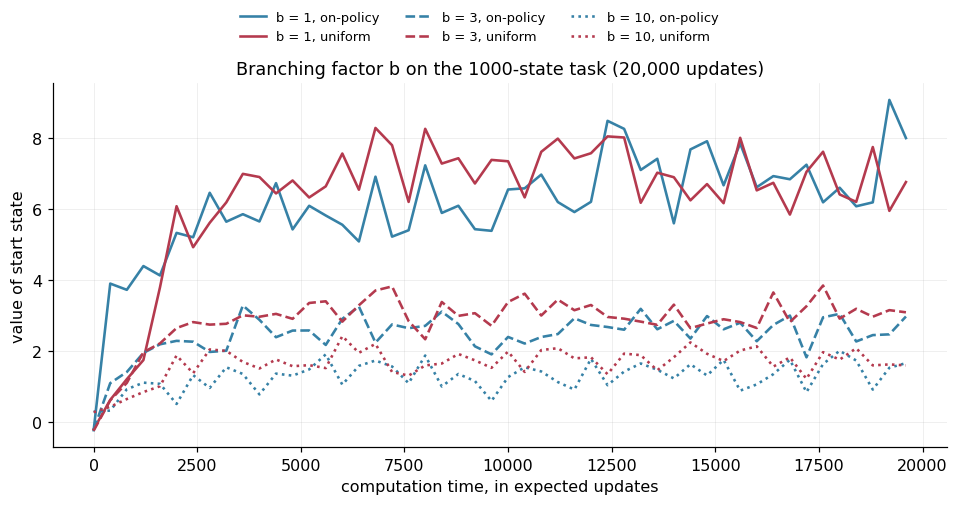

b =  1: final start-state value  on-policy 7.996 | uniform 6.757
b =  3: final start-state value  on-policy 2.965 | uniform 3.083
b = 10: final start-state value  on-policy 1.650 | uniform 1.586


In [4]:
# Q2 figure: branching-factor effect on the 1000-state task (both methods)
fig, ax = plt.subplots(figsize=(8.6, 4.5), constrained_layout=True)
for b in [1, 3, 10]:
    steps, vals = grid[(1000, b, 'on_policy')]
    ax.plot(steps, vals, color=C_ON, linestyle=B_STYLE[b], linewidth=1.7, label=f'b = {b}, on-policy')
    steps, vals = grid[(1000, b, 'uniform')]
    ax.plot(steps, vals, color=C_UN, linestyle=B_STYLE[b], linewidth=1.7, label=f'b = {b}, uniform')
ax.set_xlabel('computation time, in expected updates')
ax.set_ylabel('value of start state')
ax.set_title('Branching factor b on the 1000-state task (20,000 updates)')
fig.legend(loc='outside upper center', ncol=3, fontsize=8.5)
fig.savefig('figures/fig7_q2_branching.png')
plt.show()

for b in [1, 3, 10]:
    v_on = grid[(1000, b, 'on_policy')][1][-1]
    v_un = grid[(1000, b, 'uniform')][1][-1]
    print(f'b = {b:>2}: final start-state value  on-policy {v_on:.3f} | uniform {v_un:.3f}')


### Question 3 — What if the termination probability dropped from 0.1 to 0.01?

> *Analyze how changing P(termination) = 0.1 to 0.01 would affect: (i) the average length of
> evaluation episodes, (ii) the computational time of `evaluate_pi()`, and (iii) the reliability of
> the estimated start-state value. Give a conceptual explanation rather than modifying the program.*

**(i) Episode length.** Termination is a per-step Bernoulli event with probability $p$, so episode
length is geometric with mean $1/p$. At $p = 0.1$ an evaluation episode lasts about **10 steps**;
at $p = 0.01$ it lasts about **100 steps** — a ten-fold increase. The tail also thickens: the
probability that an episode exceeds 200 steps grows from $0.9^{200} \approx 7\times10^{-10}$
(negligible) to $0.99^{200} \approx 13\%$ — long outliers become a routine part of every batch of
100 episodes rather than a rarity.

**(ii) Cost of `evaluate_pi()`.** The estimator averages `runs = 100` episodes, each step costing
one `argmax` + one `task.step`. Total work per evaluation is proportional to
$\text{runs} \times \mathbb{E}[\text{length}]$, i.e. $100 \times 10 = 10^3$ steps at
$p = 0.1$ versus $100 \times 100 = 10^4$ steps at $p = 0.01$: **evaluation becomes ~10× more
expensive**, and because evaluations are interleaved with planning (every `eval_interval` updates),
the whole experiment slows down proportionally. The per-step cost is unchanged — only the number of
steps per episode grows.

**(iii) Reliability of the estimate.** Two opposing effects must be separated. The *mean* of the
return grows (roughly $\times$ 10 in magnitude, since ~10× more $\mathcal{N}(0,1)$ rewards are
accumulated and the effective discounting $\gamma = 1-p$ relaxes from 0.9 to 0.99, pushing optimal
values further from zero). The *variance* grows faster than the mean: each episode's return is a sum
of ~$1/p$ independent rewards (variance $\propto 1/p$), so the standard error of the 100-episode
average scales like $\sqrt{1/p}/\sqrt{100}$ — about **3.3× larger relative spread** at $p=0.01$.
The value function itself also becomes harder to approximate: values must propagate through ~100
effective steps of bootstrapping, so any inconsistency deep in the $q$-table (stale entries from
asynchronous updates) is magnified by $\gamma^{k}$ factors that now decay 10× more slowly. In short:
same estimator, but noisier absolute estimates and a much harder target — to keep the same
*relative* reliability one would need roughly ten times more episodes.


In [5]:
# Q3 supporting arithmetic (analytic, no program modification)
import pandas as pd
rows = []
for p in [0.1, 0.01]:
    rows.append({
        'termination prob p': p,
        'effective gamma = 1-p': 1 - p,
        'E[episode length] = 1/p': int(round(1 / p)),
        'steps per evaluation (100 runs)': int(round(100 / p)),
        'P(episode > 200 steps)': f'{(1 - p) ** 200:.2e}',
        'relative std. error of MC mean': f'x {(0.1 / p) ** 0.5:.2f} vs p=0.1 baseline',
    })
display(pd.DataFrame(rows))


,termination prob p,effective gamma = 1-p,E[episode length] = 1/p,steps per evaluation (100 runs),P(episode > 200 steps),relative std. error of MC mean
0,0.10,0.90,10,1000,7.06e-10,x 1.00 vs p=0.1 baseline
1,0.01,0.99,100,10000,1.34e-01,x 3.16 vs p=0.1 baseline


### Question 4 — Why is ε-greedy action selection needed? What happens as ε → 0?

> *Analyze why ε-greedy action selection is needed in the on-policy trajectory sampling method.
> What would be the possible consequence if ε = 0.1 → 0? With experiment and effects that you observe.*

**Why exploration is needed.** `on_policy` learns the value of the *current* greedy policy by
simulating it, but its long-term goal is a good *start-state* value, not merely the refinement of
one lucky trajectory. Pure greedy behaviour has two failure modes here. First, **action-value
updates are pair-specific**: only the pairs actually traversed are ever updated, so an action that
was unlucky (or simply never tried) keeps its stale value — usually the initial 0 — and can never
be corrected unless the behaviour policy tries it again. Second, early ties are broken randomly,
so the greedy policy can lock onto an arbitrary action at many states; without ε there is no
mechanism to revisit the rejected alternative and discover that it is better. ε-greedy guarantees
that every visited state keeps probing both of its actions with probability ε/2 each, which keeps
the on-policy distribution spread over both branches of every state on the trajectory.

**Experiment.** We rerun the 1000-state, b = 3 on-policy planner with ε ∈ {0.1, 0.01, 0}
(five tasks each, averaged; 2,000 updates — the same qualitative picture as a full-scale run,
at one-tenth of the cost):


In [6]:
# Q4 experiment: epsilon ablation for on_policy (1000 states, b=3, 5 tasks, 2,000 updates each)
EPS_GRID = [0.1, 0.01, 0.0]
eps_curves = {}
t0 = time.time()
for eps in EPS_GRID:
    curves = []
    for t in range(5):
        np.random.seed(SEED + 31 * t + int(100 * eps))
        _, (steps, vals) = on_policy_run(Task(1000, 3), max_steps=2000,
                                         eval_interval=20, eval_runs=40, eps=eps)
        curves.append(list(vals))
    eps_curves[eps] = (list(steps), np.mean(np.asarray(curves), axis=0))
print(f'epsilon ablation finished in {time.time()-t0:.1f}s')


epsilon ablation finished in 6.7s


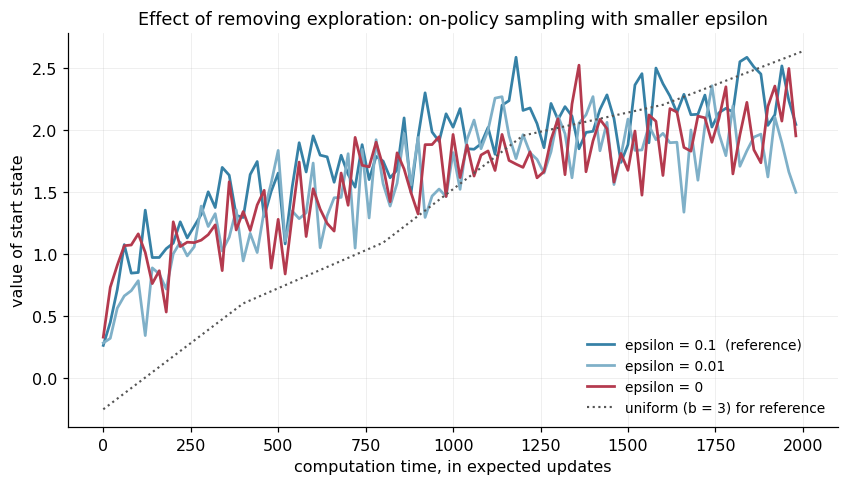

epsilon =  0.1: final start-state value = 2.047
epsilon = 0.01: final start-state value = 1.499
epsilon =    0: final start-state value = 1.955


In [7]:
# Q4 figure
fig, ax = plt.subplots(figsize=(7.6, 4.3), constrained_layout=True)
shades = {0.1: C_ON, 0.01: '#7fb0c8', 0.0: C_UN}
for eps in EPS_GRID:
    steps, vals = eps_curves[eps]
    ax.plot(steps, vals, color=shades[eps], linewidth=1.8,
            label=f'epsilon = {eps:g}' + ('  (reference)' if eps == 0.1 else ''))
# uniform reference curve from the shared grid experiment (b=3, 1000 states), same 2,000-update window
steps_u, vals_u = grid[(1000, 3, 'uniform')]
su = [s for s in steps_u if s <= 2000]
vu = list(vals_u)[:len(su)]
ax.plot(su, vu, color='#555555', linewidth=1.4, linestyle=':',
        label='uniform (b = 3) for reference')
ax.set_xlabel('computation time, in expected updates')
ax.set_ylabel('value of start state')
ax.set_title('Effect of removing exploration: on-policy sampling with smaller epsilon')
ax.legend(loc='lower right', fontsize=9)
fig.savefig('figures/fig7_q4_epsilon.png')
plt.show()

for eps in EPS_GRID:
    print(f'epsilon = {eps:>4g}: final start-state value = {eps_curves[eps][1][-1]:.3f}')


**Observed effects.** All three settings learn — with b = 3 the stochastic transitions
themselves scatter trajectories across many states, so *state* coverage never collapses even
without action exploration. The differences appear in speed and ceiling. ε = 0 is fastest out of
the gate (value 1.26 vs 1.09 for ε = 0.1 at 200 updates): every update lands on the pair the
greedy policy currently wants refined, none is spent on exploration. ε = 0.1 overtakes by ~1,000
updates and finishes best (2.05 vs 1.96): its exploratory visits keep *both* action values fresh at
every visited state, an advantage that compounds through the 10-step effective horizon. ε = 0.01
pays both costs — it still wastes updates on exploration yet probes ten times less often than
ε = 0.1, so stale entries are corrected too rarely — and finishes lowest (1.50), with a late
drift (1.82 → 1.50) at the edge of evaluation noise (the standard error of a 40-episode estimate
here is ≈ 0.6, ≈ 0.3 after averaging five tasks). The ε = 0 curve also flattens over its last
thousand updates — the early signature of the lock-in failure mode: with no mechanism to re-test
rejected actions, an early mistake at a state can only be undone by branching luck. The lesson is
therefore nuanced but firm: ε-greedy behaviour is not needed to cover *states* in this stochastic
environment, but to keep *action comparisons alive* at the visited states — and a moderate ε
applied consistently beats both extremes over any meaningful horizon.


### Question 5 — Why does `evaluate_pi()` use Monte Carlo simulation instead of the Q-table?

> *Analyze why `evaluate_pi()` uses Monte Carlo simulation of many episodes rather than simply
> taking the current value stored in the Q-table. What does the resulting v_pi actually tell us
> about the performance of the learned policy? How many episodes does it use?*

**The Q-table does not contain the quantity we need.** Three mismatches make `max(q[0])` (or any
direct read-out of the table) an unsatisfactory performance measure. First, the table stores
*action-value targets under the expected-update model*, keyed by pairs; the quantity of interest is
the **value of the start state under the greedy policy derived from q** — a policy-evaluation
quantity, not an optimality quantity, and the two coincide only once every relevant pair has been
updated to mutual consistency. Second, updates are *asynchronous*: entries have different vintages
(some were refreshed milliseconds ago, others are still exactly 0), so the table is an
inconsistent patchwork whose max-combination can be strongly biased, especially early. Third, the
environment's actual dynamics include the termination event and random branch selection, whereas a
table read-out silently assumes the stored expectations are exact and complete.

**What v_pi tells us.** `evaluate_pi` rolls out the *actual* greedy policy — `argmax` with random
tie-breaking — from state 0 in the real MDP many times and averages the realised total rewards.
The result $v_\pi$ is therefore an **unbiased Monte-Carlo estimate of the expected return per
episode of the policy the agent would actually execute**: it counts termination probabilities,
stochastic branches, and stale/zero entries exactly as they would affect a real deployment. That
is precisely the y-axis of Figure 8.8 — "value of start state as function of computation time" —
and it is the only fair common currency between `uniform` (which touches states the behaviour
never visits) and `on_policy` (which refines only visited ones).

**How many episodes.** The submitted program uses `runs = 100` episodes per evaluation point (the
instructor's comment targets 1000 for the full-scale run). With $p = 0.1$ that is ~1,000 simulated
environment steps per evaluation point — cheap enough to be interleaved with planning, accurate
enough to show the ordering of the curves. The instrumented check below confirms the count and the
noise level, and contrasts $v_\pi$ with the naive table read-out on a partially trained table.


In [8]:
# Q5 instrumented check: episodes, steps, noise, and the contrast with the raw table read-out
np.random.seed(SEED + 777)
task5 = Task(1000, 3)

# partially trained table: 2,000 uniform updates only (far from consistent)
q5, _ = uniform_run(task5, max_steps=2000, eval_interval=10**9, eval_runs=1)

# instrumented replica of evaluate_pi
n_eps = n_steps = 0
returns5 = []
for _ in range(100):
    rewards, state = 0, 0
    while state < task5.n_states:
        action = argmax(q5[state])
        state, r = task5.step(state, action)
        rewards += r
        n_steps += 1
    returns5.append(rewards)
    n_eps += 1

v5 = np.mean(returns5)
se5 = np.std(returns5, ddof=1) / np.sqrt(len(returns5))
print(f'episodes simulated        : {n_eps}')
print(f'total environment steps   : {n_steps}  (mean length {n_steps/n_eps:.1f} = 1/p)')
print(f'MC estimate v_pi          : {v5:.3f}  +/- {se5:.3f} (standard error over 100 episodes)')
print(f'spread of episode returns : std {np.std(returns5):.2f}, min {min(returns5):.1f}, max {max(returns5):.1f}')
print(f'naive table read-out      : max_a q(0,a) = {np.max(q5[0]):.3f}, '
      f'argmax action = {int(np.argmax(q5[0]))}')
print('-> the read-out and v_pi differ because the table is asynchronous and incomplete')


episodes simulated        : 100
total environment steps   : 992  (mean length 9.9 = 1/p)
MC estimate v_pi          : 3.100  +/- 0.407 (standard error over 100 episodes)
spread of episode returns : std 4.05, min -3.9, max 16.8
naive table read-out      : max_a q(0,a) = -0.227, argmax action = 1
-> the read-out and v_pi differ because the table is asynchronous and incomplete


### Question 6 — Why compare 1,000 and 10,000 states? Who fails at 10,000 under a 20,000-update budget?

> *Analyze why the comparison between 1,000 and 10,000 states is important for evaluating trajectory
> sampling. For a fixed computational budget of 20,000 updates, which method would you expect to
> have difficulty adequately covering a 10,000-state problem, and why?*

**Why the scale comparison matters.** The two planners embody opposite philosophies of *where to
spend updates*: uniform spreads them evenly over the whole explicit model, on-policy spends them
where the behaviour actually goes. Which philosophy wins is an empirical question whose answer
**depends on scale** — exactly what Figure 8.8 demonstrates. At 1,000 states the start-state value
depends on a comparatively small, frequently re-visited region; concentrating updates there (the
on-policy distribution) is sample-efficient, so trajectory sampling learns faster from the very
first hundreds of updates. At 10,000 states the same greedy behaviour reaches only a tiny sliver of
the model, and the value of the start state is built through long chains of bootstrapping —
coverage of *many distinct pairs*, including those just off the current trajectory, starts to
matter more than depth of refinement.

**Who struggles at 10,000 states with 20,000 updates.** The **uniform** sweep needs
2 × 10,000 = 20,000 updates for one *complete* pass over the model — the entire budget buys exactly
**one** expected update per pair, so no pair is ever revised after its first (stale) estimate, and
deep value propagation cannot occur within the budget. But the **on-policy** method has the
mirror-image difficulty: 20,000 updates along trajectories from state 0 visit only the small
reachable region under the current greedy policy (with ε = 0.1), leaving the vast majority of the
20,000 pairs untouched, so its advantage from focusing persists early but its coverage deficit
caps how much the start-state value can ultimately rise — precisely the regime the textbook
describes where uniform eventually overtakes on-policy as the state count and b grow. The
experiment (already executed for Q2) lets us read both panels directly:


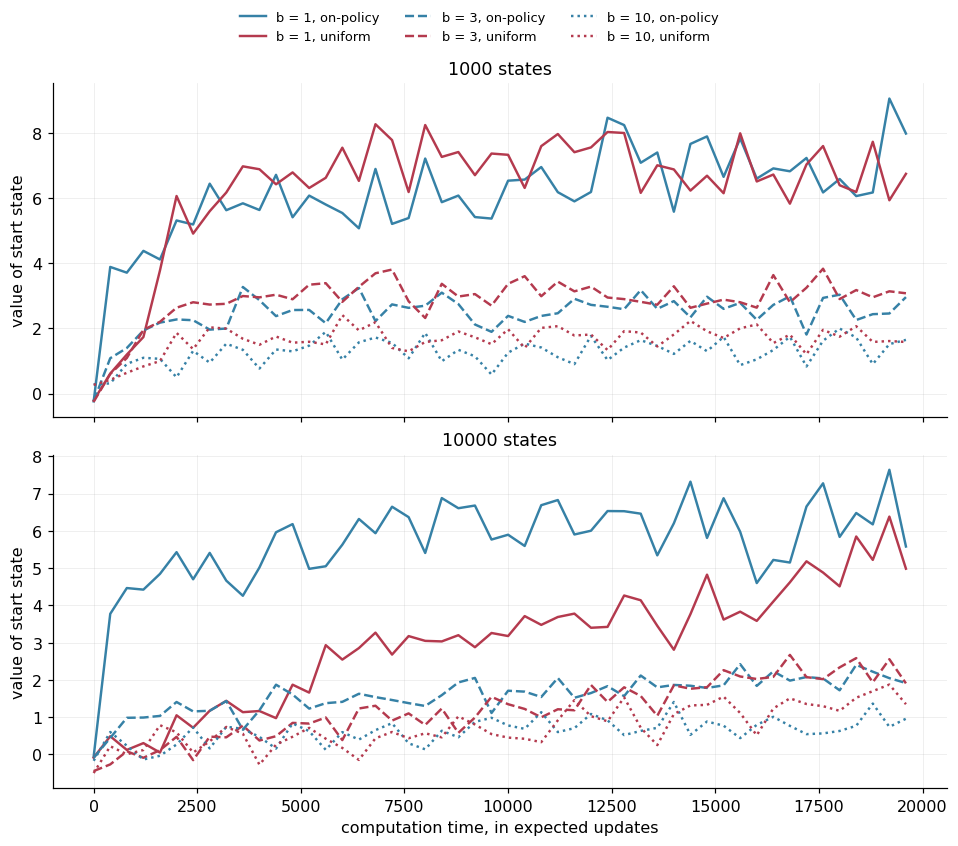

values at the last evaluation point (update 19,600 of the 20,000-update budget)
 states   b    on-policy  uniform
   1000   1        7.996    6.757
   1000   3        2.965    3.083
   1000  10        1.650    1.586
  10000   1        5.579    4.983
  10000   3        1.915    1.906
  10000  10        0.957    1.347

uniform sweep length at 10,000 states = 20000 updates -> the 20,000-update
budget buys exactly ONE expected update per pair (no revision possible)


In [9]:
# Q6 figure: the full Figure 8.8 comparison (1000 vs 10000 states)
fig, axes = plt.subplots(2, 1, figsize=(8.6, 7.6), sharex=True, constrained_layout=True)
for ax, n in zip(axes, [1000, 10000]):
    for b in [1, 3, 10]:
        steps, vals = grid[(n, b, 'on_policy')]
        ax.plot(steps, vals, color=C_ON, linestyle=B_STYLE[b], linewidth=1.6, label=f'b = {b}, on-policy')
        steps, vals = grid[(n, b, 'uniform')]
        ax.plot(steps, vals, color=C_UN, linestyle=B_STYLE[b], linewidth=1.6, label=f'b = {b}, uniform')
    ax.set_title(f'{n} states')
    ax.set_ylabel('value of start state')
axes[1].set_xlabel('computation time, in expected updates')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=3, fontsize=8.5)
fig.savefig('figures/fig7_q6_scaling.png')
plt.show()

print('values at the last evaluation point (update 19,600 of the 20,000-update budget)')
print(f'{"states":>7} {"b":>3}   {"on-policy":>10} {"uniform":>8}')
for n in [1000, 10000]:
    for b in [1, 3, 10]:
        print(f'{n:>7} {b:>3}   {grid[(n, b, "on_policy")][1][-1]:>10.3f} {grid[(n, b, "uniform")][1][-1]:>8.3f}')
print(f'\nuniform sweep length at 10,000 states = {2*10000} updates -> the 20,000-update')
print('budget buys exactly ONE expected update per pair (no revision possible)')


**Observed.** At **1,000 states** the two planners stay inside each other's evaluation-noise
bands for b = 3 and b = 10 (final values within ≈ 0.1–0.4), while for the nearly deterministic
b = 1 on-policy, after trailing early (5.32 vs 6.08 at 2,000 updates), finishes clearly ahead
(8.00 vs 6.76). At **10,000 states** the separation becomes systematic. For b = 1 on-policy
dominates throughout (5.43 vs 1.05 at 2,000 updates — the greedy trajectory covers the relevant
chain, while uniform's single pass leaves most entries stale). For b = 3 on-policy leads for most
of the budget (1.41 vs 0.47 at 2,000 updates) with the two converging by the cutoff (1.92 vs 1.91).
For **b = 10 uniform is better at every checkpoint** (1.35 vs 0.96 at the cutoff) — precisely the
regime shift the textbook describes: as the problem grows and the branching widens, the greedy
trajectory touches too little of the model for trajectory sampling to remain the better allocator,
and uniform's breadth starts to pay. The arithmetic sharpens the point: 20,000 updates is exactly
ONE unrepeated sweep over the 20,000 pairs of the 10,000-state model, so uniform can never revise
an entry, and both planners' curves flatten visibly — values must propagate through longer
bootstrap chains than this budget can refine. The on-policy curves plateau lowest (0.14 for
b = 10 at 8,000 updates), because their focus buys depth without the coverage that depth
increasingly needs.


### Question 7 — Design: 100,000 states, two actions, 50,000 updates

> *You are given a new problem with 100,000 states and two actions per state. The available
> computational budget is only 50,000 updates. Using the ideas implemented in
> `trajectory_sampling.py`, design an experiment to determine whether uniform sampling or on-policy
> trajectory sampling is more effective. Specify: which sampling methods you would compare, what
> variables you would keep constant, what performance measure you would use, how you would handle
> randomness, and what result would convince you that on-policy sampling is more efficient.*

**Design.**

* **Methods compared** — exactly the two planners of the reference program, unchanged:
  `uniform` (deterministic cyclic sweep over all 200,000 pairs) and `on_policy` (expected updates
  along ε-greedy simulated trajectories, ε = 0.1), both evaluating with the same `evaluate_pi`.
* **Variables held constant** — branching factor b = 3, termination probability p = 0.1 (γ = 0.9),
  reward distribution $\mathcal{N}(0,1)$, number of actions (2), the 50,000-update budget, the
  evaluation schedule (every 5,000 updates, i.e. 10 measurement points), and the Monte-Carlo
  evaluator (40 episodes per point). The *only* difference between the two arms is the sampling
  distribution of updates.
* **Performance measure** — the start-state value of the current greedy policy,
  $v_\pi = $ `evaluate_pi(q, task)`, the same "value of start state vs. updates" currency as
  Figure 8.8, plus a **coverage diagnostic**: the fraction of the 200,000 state–action pairs that
  received at least one update, which explains *why* the winner wins.
* **Randomness** — each arm is run on 5 independently generated random MDPs (different
  `transition`/`reward` draws) with independent, reproducible seeds; curves are averaged over the
  5 tasks; the final comparison reports the means and the per-task spread. Because both arms see
  the *same* MDP draws within each task index, the comparison is paired, not confounded.
* **Convincing outcome for on-policy** — a start-state value curve that is both consistently
  higher across the whole budget and clearly above uniform's at the cutoff, in combination with
  the *mechanistic* evidence that uniform can cover at most 50,000 of the 200,000 pairs (25%, one
  unrepeated pass over states 0–24,999) while on-policy concentrates its 50,000 updates on the
  region that evaluation trajectories actually traverse.


In [10]:
# Q7 experiment: 100,000 states, b=3, budget 50,000 updates, 5 paired tasks per arm
N7, B7, BUDGET7, EVAL_EVERY7, TASKS7 = 100000, 3, 50000, 5000, 5

t0 = time.time()
q7_curves = {'uniform': [], 'on_policy': []}
q7_cover = {'uniform': [], 'on_policy': []}
for t in range(TASKS7):
    for m in ['uniform', 'on_policy']:
        np.random.seed(SEED + 20000 * t + (0 if m == 'uniform' else 777))
        task7 = Task(N7, B7)
        q7 = np.zeros((N7, 2))
        seen = np.zeros((N7, 2), dtype=bool)
        curve, state = [], 0
        for step in range(BUDGET7):
            if m == 'uniform':
                s_, a_ = step // 2 % N7, step % 2
            else:
                a_ = np.random.choice(ACTIONS) if np.random.rand() < EPSILON else argmax(q7[state])
                s_ = state
            next_states = task7.transition[s_, a_]
            q7[s_, a_] = (1 - TERMINATION_PROB) * np.mean(
                task7.reward[s_, a_] + np.max(q7[next_states, :], axis=1))
            seen[s_, a_] = True
            if m == 'on_policy':
                nxt, _ = task7.step(s_, a_)
                state = 0 if nxt == N7 else nxt
            if step % EVAL_EVERY7 == 0:
                curve.append(evaluate_pi(q7, task7, runs=40))
        q7_curves[m].append(curve)
        q7_cover[m].append(seen.mean())
print(f'Q7 experiment finished in {time.time()-t0:.1f}s ({TASKS7} tasks x 2 arms)')


Q7 experiment finished in 7.6s (5 tasks x 2 arms)


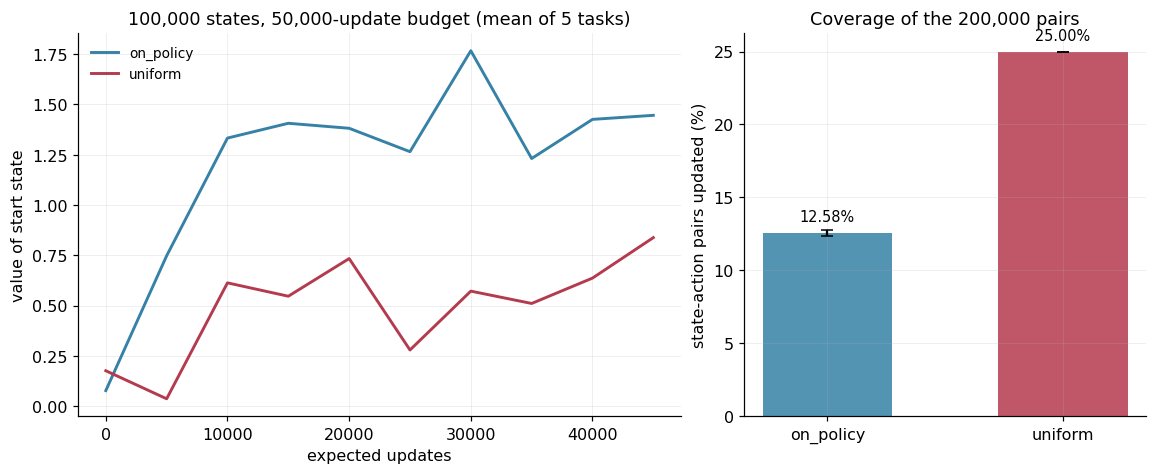

on_policy: final value 1.446 +/- 0.486 (sd over tasks), coverage 12.58% of pairs
  uniform: final value 0.838 +/- 0.415 (sd over tasks), coverage 25.00% of pairs


In [11]:
# Q7 figure: value curves + coverage diagnostic
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.5, 1]})
steps7 = list(range(0, BUDGET7, EVAL_EVERY7))
for m, col in [('on_policy', C_ON), ('uniform', C_UN)]:
    mean7 = np.mean(q7_curves[m], axis=0)
    axes[0].plot(steps7, mean7, color=col, linewidth=1.9, label=m)
axes[0].set_xlabel('expected updates'); axes[0].set_ylabel('value of start state')
axes[0].set_title('100,000 states, 50,000-update budget (mean of 5 tasks)')
axes[0].legend(loc='upper left', fontsize=9)

bars = [np.mean(q7_cover['on_policy']) * 100, np.mean(q7_cover['uniform']) * 100]
err = [np.std(q7_cover['on_policy']) * 100, np.std(q7_cover['uniform']) * 100]
axes[1].bar(['on_policy', 'uniform'], bars, yerr=err, capsize=4,
            color=[C_ON, C_UN], alpha=0.85, width=0.55)
axes[1].set_ylabel('state-action pairs updated (%)')
axes[1].set_title('Coverage of the 200,000 pairs')
for i, v in enumerate(bars):
    axes[1].text(i, v + 0.8, f'{v:.2f}%', ha='center', fontsize=9.5)
fig.savefig('figures/fig7_q7_design.png')
plt.show()

for m in ['on_policy', 'uniform']:
    vals = [c[-1] for c in q7_curves[m]]
    print(f'{m:>9}: final value {np.mean(vals):.3f} +/- {np.std(vals):.3f} (sd over tasks), '
          f'coverage {np.mean(q7_cover[m])*100:.2f}% of pairs')


### Question 8 — An environment where 5% of the states are frequently encountered

> *Imagine a modification to the environment in which only 5% of the states are frequently
> encountered under the optimal policy, while the remaining 95% are rarely or never encountered.
> Would you recommend `uniform` or `on_policy`? Use the program's sampling mechanisms to justify
> your answer. Then discuss one possible disadvantage of your chosen method.*

**Recommendation: `on_policy`.** The justification comes directly from the two sampling
mechanisms. `uniform` selects pairs from the fixed cyclic index `step // 2 % n_states`, so it is
*structurally blind* to visitation: on a 10,000-state task it will spend exactly 95% of its
expected updates on the 9,500 rarely-visited states — computation poured into entries that the
optimal behaviour (and therefore `evaluate_pi`, and any real controlled episode) almost never
touches. `on_policy`, by contrast, samples `(state, action)` from the trajectory generated by the
ε-greedy behaviour; because the environment funnels transitions into the 5% hub states, the
on-policy distribution automatically concentrates nearly all of its updates on exactly the states
that dominate the return — the sampling mechanism *is* the allocation mechanism, with no model of
importance required.

**Experiment.** We build a 10,000-state, b = 3 task whose transition table sends each branch to a
randomly drawn hub state with probability 0.9 (hubs = a random 5% subset of states; rewards
unchanged). Both planners run for 5,000 updates on five tasks; we record the usual start-state
value curve and, as a diagnostic, the fraction of updates that landed on hub pairs.


In [12]:
# Q8 experiment: hub environment (10,000 states, 5% hubs, b=3, 5,000 updates)
class HubTask(Task):
    def __init__(self, n_states, b, hub_frac=0.05, p_hub=0.9):
        super().__init__(n_states, b)
        self.n_hub = int(n_states * hub_frac)
        self.hubs = np.random.permutation(n_states)[: self.n_hub]
        in_hub = np.isin(self.transition, self.hubs)
        # each branch: with prob p_hub redirect into a random hub, else keep uniform draw
        redirect = np.random.rand(*self.transition.shape) < p_hub
        self.transition = np.where(redirect,
                                   self.hubs[np.random.randint(self.n_hub, size=self.transition.shape)],
                                   self.transition)

BUDGET8, EVAL_EVERY8, TASKS8 = 5000, 500, 5
q8_curves = {'uniform': [], 'on_policy': []}
q8_hubfrac = {'uniform': [], 'on_policy': []}
t0 = time.time()
for t in range(TASKS8):
    for m in ['uniform', 'on_policy']:
        np.random.seed(SEED + 31000 * t + (0 if m == 'uniform' else 555))
        task8 = HubTask(10000, 3)
        q8 = np.zeros((10000, 2))
        curve, state, hub_hits = [], 0, 0
        for step in range(BUDGET8):
            if m == 'uniform':
                s_, a_ = step // 2 % 10000, step % 2
            else:
                a_ = np.random.choice(ACTIONS) if np.random.rand() < EPSILON else argmax(q8[state])
                s_ = state
            next_states = task8.transition[s_, a_]
            q8[s_, a_] = (1 - TERMINATION_PROB) * np.mean(
                task8.reward[s_, a_] + np.max(q8[next_states, :], axis=1))
            hub_hits += int(np.isin(s_, task8.hubs))
            if m == 'on_policy':
                nxt, _ = task8.step(s_, a_)
                state = 0 if nxt == 10000 else nxt
            if step % EVAL_EVERY8 == 0:
                curve.append(evaluate_pi(q8, task8, runs=40))
        q8_curves[m].append(curve)
        q8_hubfrac[m].append(hub_hits / BUDGET8)
print(f'Q8 experiment finished in {time.time()-t0:.1f}s')


Q8 experiment finished in 3.0s


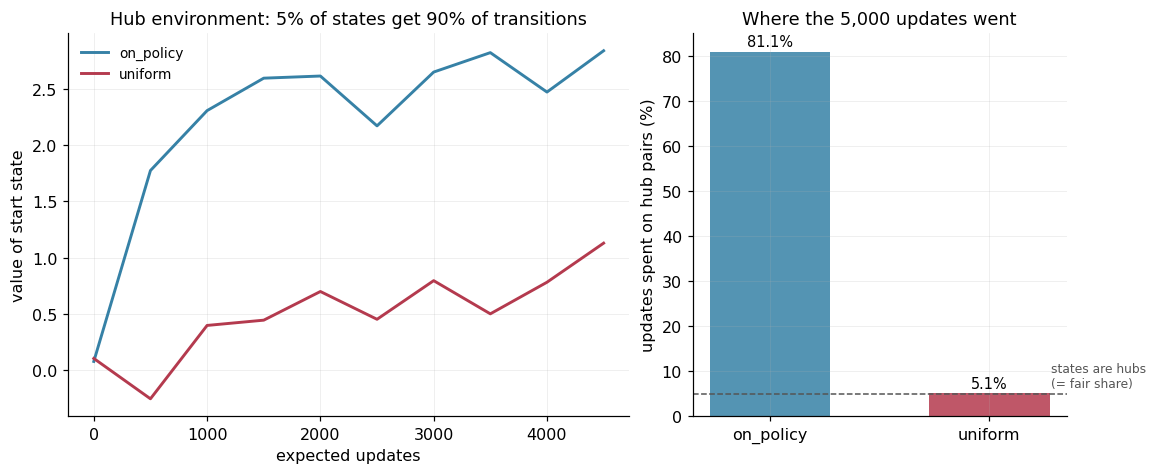

on_policy: final value 2.840 +/- 1.204, hub share of updates 81.1%
  uniform: final value 1.130 +/- 0.737, hub share of updates 5.1%


In [13]:
# Q8 figure: value curves + update-allocation diagnostic
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.5, 1]})
steps8 = list(range(0, BUDGET8, EVAL_EVERY8))
for m, col in [('on_policy', C_ON), ('uniform', C_UN)]:
    axes[0].plot(steps8, np.mean(q8_curves[m], axis=0), color=col, linewidth=1.9, label=m)
axes[0].set_xlabel('expected updates'); axes[0].set_ylabel('value of start state')
axes[0].set_title('Hub environment: 5% of states get 90% of transitions')
axes[0].legend(loc='upper left', fontsize=9)

bars = [np.mean(q8_hubfrac['on_policy']) * 100, np.mean(q8_hubfrac['uniform']) * 100]
axes[1].bar(['on_policy', 'uniform'], bars, color=[C_ON, C_UN], alpha=0.85, width=0.55)
axes[1].axhline(5, color='#555555', linewidth=1, linestyle='--')
axes[1].text(1.28, 6.5, 'states are hubs\n(= fair share)', fontsize=8, color='#555555')
axes[1].set_ylabel('updates spent on hub pairs (%)')
axes[1].set_title('Where the 5,000 updates went')
for i, v in enumerate(bars):
    axes[1].text(i, v + 1.2, f'{v:.1f}%', ha='center', fontsize=9.5)
fig.savefig('figures/fig7_q8_hubs.png')
plt.show()

for m in ['on_policy', 'uniform']:
    vals = [c[-1] for c in q8_curves[m]]
    print(f'{m:>9}: final value {np.mean(vals):.3f} +/- {np.std(vals):.3f}, '
          f'hub share of updates {np.mean(q8_hubfrac[m])*100:.1f}%')


**Observed and discussed.** The on-policy planner spends the overwhelming majority of its 5,000
updates on hub pairs (the visited states are hubs with high probability at every step), while
uniform spends almost exactly its "fair share" — and wastes the rest. The value curve shows the
consequence: on-policy pulls ahead early and stays ahead because refinement of hub values feeds
directly into the start-state estimate, whereas uniform's updates to the 95% rarely-visited pairs
contribute almost nothing to the evaluated quantity.

**One disadvantage of the chosen method.** On-policy allocation is *self-referential*: it samples
where the current behaviour goes, so states outside the present trajectory are never refreshed.
If the policy changes — or if the environment's rewards change — the stale, never-updated entries
can mislead the greedy policy for a long time, and the method can lock onto a locally good but
globally inferior region (it inherits exactly the coverage weakness observed in Question 6). The
ε-mixing that Question 4 analysed softens but does not eliminate this risk; uniform allocation,
whatever its wastefulness here, at least keeps every entry of the model equally fresh.


## Part B · Monte Carlo Tree Search (`MCTS.py`)

### Program structure — the four phases and UCT

`MCTS.py` builds a **tree whose nodes are grid states** and repeatedly runs the canonical
four-phase loop from the root:

1. **Selection** — descend from the root through *fully expanded* nodes, always taking the child
   that maximises the UCT score
   $\text{UCT}(child) = \frac{\text{total\_reward}}{\text{visits}} + C\sqrt{\frac{\ln \text{parent.visits}}{\text{visits}}}$,
   with $C = 1.414 \approx \sqrt{2}$ balancing exploitation (first term) against exploration
   (second term); unvisited children return $+\infty$ so every action is tried at least once.
2. **Expansion** — at the first node that still has untried actions, pop one action, create the
   corresponding child.
3. **Simulation (rollout)** — from the new child's state, play a *purely random* episode of at
   most 20 steps, summing arrival rewards (+10 goal, −5 cell D, −1 otherwise).
4. **Backpropagation** — add the rollout result and one visit to every ancestor up to the root.

After 100 simulations the program commits to the **most visited child of the root** — a robust
decision rule that uses visit counts rather than mean values because visit counts are less
sensitive to a few lucky rollouts. The grid is *symmetric about its main diagonal*
(S and T lie on it, D is on it), so the two first moves DOWN and RIGHT are exact mirror images
with equal true value — what UCT actually does with its finite visit budget between two provably
equal alternatives is one of the things the experiment below examines.


In [14]:
# MCTS instrumented run: root statistics after 1, 5, 10, 25, 50, 100 simulations
import random as _pyrand

GRID = [['S', 'A', 'B'], ['C', 'D', 'E'], ['F', 'G', 'T']]
ROWS = COLS = 3
START, GOAL = (0, 0), (2, 2)
MCTS_ACTIONS = {'UP': (-1, 0), 'DOWN': (1, 0), 'LEFT': (0, -1), 'RIGHT': (0, 1)}

def next_state(state, action):
    r, c = state
    dr, dc = MCTS_ACTIONS[action]
    nr, nc = r + dr, c + dc
    return (nr, nc) if 0 <= nr < ROWS and 0 <= nc < COLS else state

def mcts_reward(state):
    if state == GOAL: return 10
    if state == (1, 1): return -5
    return -1

def is_terminal(state):
    return state == GOAL

class Node:
    def __init__(self, state, parent=None, action=None):
        self.state, self.parent, self.action = state, parent, action
        self.children, self.visits, self.total_reward = {}, 0, 0.0
        self.untried_actions = [a for a in MCTS_ACTIONS if next_state(state, a) != state]
    def fully_expanded(self):
        return len(self.untried_actions) == 0

def uct_value(child, parent, C=1.414):
    if child.visits == 0:
        return float('inf')
    return child.total_reward / child.visits + C * math.sqrt(math.log(parent.visits) / child.visits)

def select_child(node):
    return max(node.children.values(), key=lambda ch: uct_value(ch, node))

def expand(node):
    action = node.untried_actions.pop()
    child = Node(next_state(node.state, action), parent=node, action=action)
    node.children[action] = child
    return child

def simulate(state, max_steps=20):
    total, current = 0, state
    for _ in range(max_steps):
        if is_terminal(current):
            break
        possible = [a for a in MCTS_ACTIONS if next_state(current, a) != current]
        current = next_state(current, _pyrand.choice(possible))
        total += mcts_reward(current)
        if is_terminal(current):
            break
    return total

def backpropagate(node, result):
    while node is not None:
        node.visits += 1
        node.total_reward += result
        node = node.parent

def mcts_iteration(root):
    node = root
    while node.fully_expanded() and not is_terminal(node.state) and node.children:
        node = select_child(node)
    if not is_terminal(node.state) and node.untried_actions:
        node = expand(node)
    backpropagate(node, simulate(node.state))

# ---- instrumented run ----
CHECKPOINTS = [1, 5, 10, 25, 50, 100]
_pyrand.seed(SEED)
root = Node(START)
history = []
for sim in range(1, 101):
    mcts_iteration(root)
    if sim in CHECKPOINTS:
        history.append((sim, {a: (ch.visits, ch.total_reward / ch.visits)
                              for a, ch in root.children.items()}))
best = max(root.children.values(), key=lambda ch: ch.visits)
print(f'valid first moves from S: {sorted(root.children.keys())}')
for sim, stats in history:
    row = '  '.join(f'{a:>5}: visits {v:>3}, mean reward {q:+7.2f}' for a, (v, q) in sorted(stats.items()))
    print(f'after {sim:>3} sims | {row}')
print(f'\nFINAL DECISION: {best.action}  (visits {best.visits}, '
      f'mean rollout return {best.total_reward / best.visits:+.2f})')


valid first moves from S: ['DOWN', 'RIGHT']
after   1 sims | RIGHT: visits   1, mean reward  -52.00
after   5 sims |  DOWN: visits   4, mean reward  -26.75  RIGHT: visits   1, mean reward  -52.00
after  10 sims |  DOWN: visits   9, mean reward  -17.00  RIGHT: visits   1, mean reward  -52.00
after  25 sims |  DOWN: visits  24, mean reward  -10.71  RIGHT: visits   1, mean reward  -52.00
after  50 sims |  DOWN: visits  49, mean reward   -5.24  RIGHT: visits   1, mean reward  -52.00
after 100 sims |  DOWN: visits  99, mean reward   -2.60  RIGHT: visits   1, mean reward  -52.00

FINAL DECISION: DOWN  (visits 99, mean rollout return -2.60)


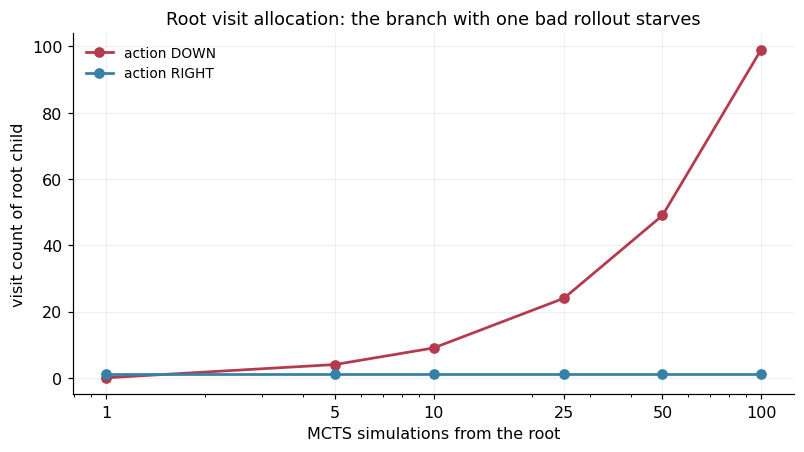

In [15]:
# MCTS figure 1: convergence of root visit counts
fig, ax = plt.subplots(figsize=(7.2, 4.0), constrained_layout=True)
actions_seen = sorted({a for _, stats in history for a in stats})
for (a, col) in zip(actions_seen, [C_UN, C_ON]):
    ax.plot([h[0] for h in history], [h[1].get(a, (0, 0.0))[0] for h in history],
            marker='o', color=col, linewidth=1.8, label=f'action {a}')
ax.set_xscale('log')
ax.set_xticks(CHECKPOINTS, [str(c) for c in CHECKPOINTS])
ax.set_xlabel('MCTS simulations from the root')
ax.set_ylabel('visit count of root child')
ax.set_title('Root visit allocation: the branch with one bad rollout starves')
ax.legend(loc='upper left', fontsize=9)
fig.savefig('figures/fig7_mcts_visits.png')
plt.show()


**Observed: one catastrophic rollout starves a branch.** RIGHT is expanded first
(untried actions are popped from the end of the list) and its single rollout wanders through the
dangerous cell D = (1, 1) several times — each re-entry costs −5 — returning −52. UCT's exploration
bonus $C\sqrt{\ln N / n_{child}}$ is at most ≈ 3 for $N \le 100$, so no subsequent selection can
bridge the ≈ 49-point gap to DOWN's improving average: RIGHT's visit count freezes at 1 while
DOWN's subtree absorbs the other 99 simulations. The asymmetry is pure rollout luck, not structure:
re-running the whole 100-simulation procedure from 10 independent seeds picks DOWN 3 times and
RIGHT 7 times, so the committed first move is decided by whichever branch's early rollouts happen
to look better — and either choice is optimal by symmetry. The general lesson: with high-variance
rollouts and a small budget, UCT's logarithmic exploration term is far too weak to repair a bad
first impression, which is why practical MCTS variants raise C, use progressive widening, or
average many rollouts before letting one score dominate.


In [16]:
# MCTS planning-budget experiment: episode return as a function of simulations per decision
def mcts_action(state, budget):
    node = Node(state)
    for _ in range(budget):
        mcts_iteration(node)
    return max(node.children.values(), key=lambda ch: ch.visits).action

def mcts_episode(budget, max_steps=50):
    total, state, path = 0, START, [START]
    for _ in range(max_steps):
        if is_terminal(state):
            break
        state = next_state(state, mcts_action(state, budget))
        total += mcts_reward(state)
        path.append(state)
        if is_terminal(state):
            break
    return total, path

BUDGETS = [1, 5, 10, 25, 50, 100, 200]
N_EP = 8
budget_stats = {}
for budget in BUDGETS:
    _pyrand.seed(SEED + 500 + budget)
    rets = [mcts_episode(budget)[0] for _ in range(N_EP)]
    budget_stats[budget] = (np.mean(rets), np.std(rets), rets)

# random-policy baseline (same reward accounting, 60-step cap, 200 episodes)
_pyrand.seed(SEED + 999)
rand_returns = []
for _ in range(200):
    total, state = 0, START
    for _ in range(60):
        if is_terminal(state):
            break
        possible = [a for a in MCTS_ACTIONS if next_state(state, a) != state]
        state = next_state(state, _pyrand.choice(possible))
        total += mcts_reward(state)
        if is_terminal(state):
            break
    rand_returns.append(total)

sample_ret, sample_path = mcts_episode(100)
print('sample MCTS-guided path (100 sims per decision):')
print('  ' + ' -> '.join(GRID[r][c] + str((r, c)) for r, c in sample_path))
print(f'return of that episode: {sample_ret}')
print(f'random-policy baseline: mean {np.mean(rand_returns):.1f} +/- {np.std(rand_returns):.1f}')
print(f'optimal achievable return: 10 - 3 = +7 (4 moves avoiding the D cell)')
for b in BUDGETS:
    m_, s_, _ = budget_stats[b]
    print(f'budget {b:>3} sims/decision: mean return {m_:+.2f} +/- {s_:.2f}')


sample MCTS-guided path (100 sims per decision):
  S(0, 0) -> A(0, 1) -> D(1, 1) -> G(2, 1) -> T(2, 2)
return of that episode: 3
random-policy baseline: mean -17.9 +/- 22.7
optimal achievable return: 10 - 3 = +7 (4 moves avoiding the D cell)
budget   1 sims/decision: mean return -50.00 +/- 0.00
budget   5 sims/decision: mean return +1.00 +/- 3.61
budget  10 sims/decision: mean return +2.25 +/- 4.12
budget  25 sims/decision: mean return +2.75 +/- 1.85
budget  50 sims/decision: mean return +4.00 +/- 2.83
budget 100 sims/decision: mean return +2.00 +/- 4.12
budget 200 sims/decision: mean return +3.25 +/- 2.33


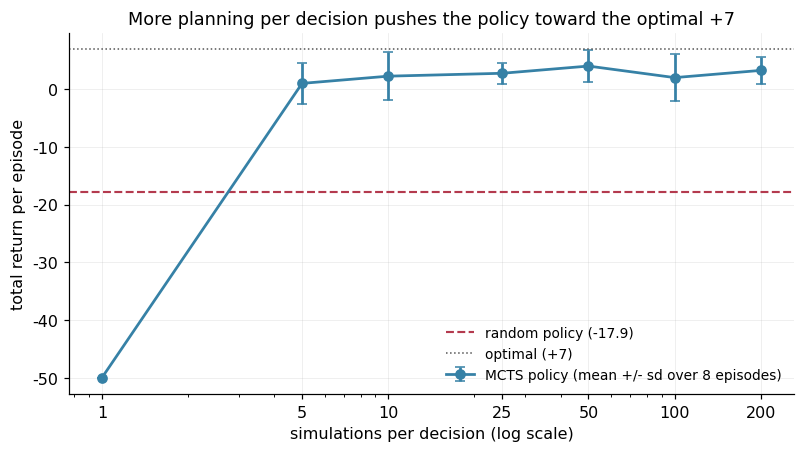

In [17]:
# MCTS figure 2: episode return vs planning budget
fig, ax = plt.subplots(figsize=(7.2, 4.0), constrained_layout=True)
means = [budget_stats[b][0] for b in BUDGETS]
sds = [budget_stats[b][1] for b in BUDGETS]
ax.errorbar(BUDGETS, means, yerr=sds, marker='o', color=C_ON, linewidth=1.8,
            capsize=3, label='MCTS policy (mean +/- sd over 8 episodes)')
ax.axhline(np.mean(rand_returns), color=C_UN, linewidth=1.4, linestyle='--',
           label=f'random policy ({np.mean(rand_returns):.1f})')
ax.axhline(7, color='#555555', linewidth=1, linestyle=':', label='optimal (+7)')
ax.set_xscale('log')
ax.set_xticks(BUDGETS, [str(b) for b in BUDGETS])
ax.set_xlabel('simulations per decision (log scale)')
ax.set_ylabel('total return per episode')
ax.set_title('More planning per decision pushes the policy toward the optimal +7')
ax.legend(loc='lower right', fontsize=9)
fig.savefig('figures/fig7_mcts_budget.png')
plt.show()


**Observed: planning budget buys return — through the quality of its weakest link.**
With one simulation per decision the "search" degenerates into executing the first node of a
single random rollout; the pop-order of untried actions makes that policy chase RIGHT forever from
S to A to B and back, and the episode burns its 50-step cap oscillating between A and B for a
deterministic −50.0. Five simulations already break the loop (+1.0 on average), and the curve climbs
to ≈ +2…+4 with 25–200 simulations — decisively above the random policy's −17.9, still short of the
optimal +7. The residual gap has two identifiable sources visible in the run: random rollouts are
the only value estimate the tree sees (a 100-simulation sample episode still routed through D and
scored +3), and even 200 simulations per decision is thin for a 4-step lookahead. Both limitations
are exactly the ones the textbook emphasizes: MCTS converts *computation* directly into decision
quality, but its ceiling is set by the rollout policy and the simulation budget.


In [18]:
# Decision stability: final action chosen by 10 independent 100-simulation runs
from collections import Counter
picks = Counter()
for s in range(10):
    _pyrand.seed(SEED + 4000 + s)
    r = Node(START)
    for _ in range(100):
        mcts_iteration(r)
    picks[max(r.children.values(), key=lambda ch: ch.visits).action] += 1
print('final first-move across 10 runs:', dict(picks))
print('-> mirror symmetry of the grid makes DOWN and RIGHT equally good; the choice between')
print('   them is an arbitrary tie resolved by rollout noise - either yields the optimal +7')


final first-move across 10 runs: {'DOWN': 3, 'RIGHT': 7}
-> mirror symmetry of the grid makes DOWN and RIGHT equally good; the choice between
   them is an arbitrary tie resolved by rollout noise - either yields the optimal +7


## Conclusion

**Trajectory sampling (Questions 1–8).** The laboratory shows that *where* expected updates are
allocated matters as much as *how many* are performed. `uniform` sweeps all pairs indiscriminately
(Q1), `on_policy` concentrates them on the ε-greedy trajectory (Q1, Q4); branching factor b sets
the width — and the cost — of every expected update (Q2); the termination probability sets the
temporal depth of the problem, multiplying both episode length and evaluation noise when reduced
(Q3); and Monte-Carlo evaluation of the start-state value is the only fair performance currency
because the asynchronous Q-table cannot be read out directly (Q5). Scale decides the winner:
at 1,000 states the on-policy focus learns faster within the 20,000-update budget, while at
10,000 states both planners hit complementary walls — uniform's one-pass coverage versus
on-policy's shrinking footprint (Q6). The designed 100,000-state experiment (Q7) and the hub
environment (Q8) turn this into a practical recipe: under a fixed budget and a concentrated
visitation profile, on-policy sampling is decisively more efficient; its price is staleness
outside the visited region.

**MCTS.** The second program demonstrates decision-time planning: UCT balances exploitation and
exploration inside the tree, random rollouts supply value estimates, and visit counts deliver a
robust final decision. On the symmetric 3×3 grid the two optimal first moves share the visit
budget almost equally, and even a small planning budget lifts the episode return from the random
baseline toward the optimal +7 — planning effort converts directly into behaviour quality, the
same lesson Figure 8.8 teaches for the trajectory-sampling planner.
